In [1]:
import polars as pl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from utils import add_min_cols, reset_start_to_zero, gpus_dict

EXPORT_DATA = True

In [2]:
df = pl.read_csv("../data/alibaba-2020/generated/merged_dataframes.csv")
df.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""8fa54171acbc9f16704c03f137ac05…","""5248e29b2b7f2b5f8b974608""",2134401,2134599,null,null,"""MISC""",8,96
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",2806218,2806331,192.551088,49.391271,"""MISC""",8,96
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",3084090,3084411,150.497242,50.949074,"""MISC""",8,96
"""8a3db37b3795c7c753963d0ef966df…","""5248e29b2b7f2b5f8b974608""",2119980,2134354,null,null,"""MISC""",8,96
"""f114ac24745ec00da7107387afc99e…","""5248e29b2b7f2b5f8b974608""",2164803,2171278,null,null,"""MISC""",8,96


In [3]:
df_gpus = df.filter(df["machine_gpu"].is_not_null())
df_gpus.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",2806218,2806331,192.551088,49.391271,"""MISC""",8,96
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",3084090,3084411,150.497242,50.949074,"""MISC""",8,96
"""7f1f4d76602d2071cb959a7ec47873…","""5248e29b2b7f2b5f8b974608""",2659273,2673034,498.010627,38.279293,"""MISC""",8,96
"""6ecadb953221add9491f244051114c…","""5248e29b2b7f2b5f8b974608""",2660994,2674496,494.623959,36.739657,"""MISC""",8,96
"""66ae3b379970ed9246766f1e7b473b…","""5248e29b2b7f2b5f8b974608""",2826419,2834615,231.566358,45.814088,"""MISC""",8,96


In [4]:
df_gpus = reset_start_to_zero(df_gpus, cols=['start_time', 'end_time'])
df.sort("start_time").head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""a62323fc633f6b2b248fa29c472f2c…","""3b127c8abb4f26e57b34af81""",1589093,2162481,null,null,"""MISC""",8,96
"""8fbbbfd39ca29ee498666bdec9d92d…","""34ff670729b854702064bdb9""",1667165,2162474,null,null,"""P100""",2,64
"""99b8757c8dad2fbd3160cb10b9df51…","""8822661a76b030d582e9bbb2""",1667165,2162480,null,null,"""P100""",2,64
"""e7b2a9571e5eba3d628eb4570de65d…","""4aa72ac9bb3b481adc47b818""",1667166,2162474,null,null,"""P100""",2,64
"""e6401695c75a761b8c17bfa7c0d259…","""df2657c90eebc406289f6dc2""",1667197,2162475,null,null,"""P100""",2,64


In [5]:
df_gpus = add_min_cols(df_gpus, cols=["start_time", "end_time"])
df_gpus

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu,start_time_min,end_time_min
str,str,i64,i64,f64,f64,str,i64,i64,i64,i64
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",792322,792435,192.551088,49.391271,"""MISC""",8,96,13205,13207
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",1070194,1070515,150.497242,50.949074,"""MISC""",8,96,17837,17842
"""7f1f4d76602d2071cb959a7ec47873…","""5248e29b2b7f2b5f8b974608""",645377,659138,498.010627,38.279293,"""MISC""",8,96,10756,10986
"""6ecadb953221add9491f244051114c…","""5248e29b2b7f2b5f8b974608""",647098,660600,494.623959,36.739657,"""MISC""",8,96,10785,11010
"""66ae3b379970ed9246766f1e7b473b…","""5248e29b2b7f2b5f8b974608""",812523,820719,231.566358,45.814088,"""MISC""",8,96,13542,13679
…,…,…,…,…,…,…,…,…,…,…
"""248987cfee3c8ad4ea3fb780f49f08…","""911caaf09597b196dd41282d""",3057577,3058855,2.701375,null,"""T4""",2,96,50960,50981
"""e6ebe6217638f700ef16608869a244…","""911caaf09597b196dd41282d""",3573493,3574885,56.40965,null,"""T4""",2,96,59558,59581
"""6fbdb1acb5f58cae52f5d9299f0c1c…","""911caaf09597b196dd41282d""",4034046,4068890,31.023871,null,"""T4""",2,96,67234,67815


In [6]:
df_gpus['end_time_min'].max()

73955

In [7]:
end_time: int = df_gpus["end_time_min"].max()

idle_usage = np.zeros(end_time)
machines_list = df_gpus["machine"].unique().to_numpy()
for machine in machines_list:
    tasks = df_gpus.filter(df_gpus["machine"] == machine)
    idle_power = gpus_dict[tasks["gpu_type"][0]].idle_power
    idle_usage += tasks["cap_gpu"][0] * idle_power
    for start, end, gpu in tasks[
        ["start_time_min", "end_time_min", "machine_gpu"]
    ].iter_rows():
        idle_usage[start:end] -= round(gpu / 100.0) * idle_power

idle_usage

array([110616., 110616., 110616., ..., 110559., 110629., 110699.])

<Axes: title={'center': 'GPU IDLE Power Consumption'}, xlabel='Time (min)', ylabel='Power (watt)'>

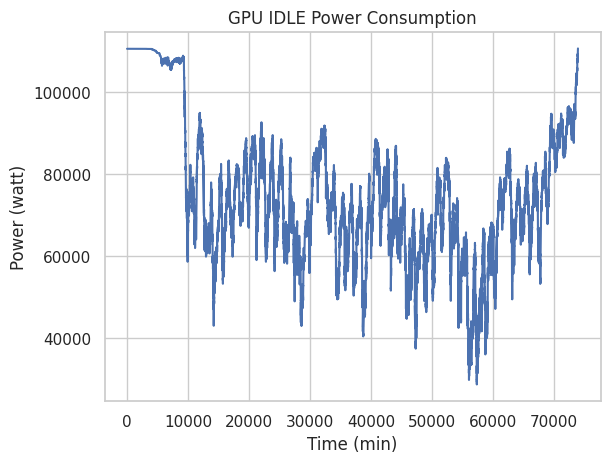

In [9]:
time = np.arange(len(idle_usage))
sns.set_theme(style='whitegrid')
plt.title("GPU IDLE Power Consumption")
plt.xlabel("Time (min)")
plt.ylabel("Power (watt)")
sns.lineplot(x=time, y=idle_usage)

In [17]:
ts = pl.DataFrame({"time": time, "power": idle_usage})

In [18]:
if EXPORT_DATA:
    ts.write_csv("../data/alibaba-2020/generated/gpu_idle_power_min.csv")